In [1]:
# Run from manual_notebooks/. Restart the kernel after changing this path.
import os

os.environ["YOLO_CONFIG_DIR"] = "../experiments/.ultralytics"


In [2]:
import time

from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import cv2
import numpy as np

from ultralytics import YOLO, settings
import torch

Проверяем имеющийся датасет

In [4]:

ROOT = Path("../")
DATASETS_DIR = ROOT / "data"
WEIGHTS_DIR = ROOT / "weights"
RUNS_DIR = ROOT / "experiments/reproductions"

DATASET_PATH = DATASETS_DIR / "tobacco_yolo"

settings.update({
    "datasets_dir": str(DATASETS_DIR.resolve()),
    "weights_dir": str(WEIGHTS_DIR.resolve()),
    "runs_dir": str(RUNS_DIR.resolve()),
})

for key in ("datasets_dir", "weights_dir", "runs_dir"):
    print(f"{key}: {settings[key]}")


print(DATASET_PATH)

datasets_dir: /home/natsusa/academic/tobacco-article/data
weights_dir: /home/natsusa/academic/tobacco-article/weights
runs_dir: /home/natsusa/academic/tobacco-article/experiments/reproductions
../data/tobacco_yolo


Устанавливаем нужный девайс

In [5]:
# Select an available device, or set explicitly: "cpu", "cuda:0", "cuda:1", "mps".
if torch.cuda.is_available():
    device = "cuda:0"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Device: {device}")


Device: cpu


Пример генерации

In [ ]:
# Очистка памяти GPU перед запуском
if torch.device(device).type == "cuda":
    with torch.cuda.device(device):
        torch.cuda.empty_cache()

model_name = "yolo26n.pt"

model = YOLO(WEIGHTS_DIR / model_name)
model.to(device)
model.info()

YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.1 GFLOPs


(260, 2572280, 0, 6.117094399999999)

обучаем как есть

In [ ]:
data_yaml = DATASET_PATH / "data.generated.yaml" 

model.train(
    data=data_yaml,
    epochs=50,  
    imgsz=640,
    batch=14,  
    device=device,
    amp=True, 
    workers=8,

    lr0=0.005,
    lrf=0.1,
    momentum=0.937,
    weight_decay=0.0005,
    warmup_epochs=5,
    warmup_momentum=0.8,
    warmup_bias_lr=0.1,
    cos_lr=True,

    augment=True,
    mosaic=0.8,
    mixup=0.3,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    flipud=0.0,
    
    patience=15, 
    save_period=1,
    cache="disk",
    plots=True
)

New https://pypi.org/project/ultralytics/8.4.190 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.81  Python-3.14.6 torch-2.12.1+cu132 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=14, bgr=0.0, box=7.5, cache=..\disk, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=..\data\tobacco_yolo\data.generated.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.005, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.3, mode=train, model=..\weights\yolo26n.pt, momentum=0.

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000022B212BBBD0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.0480


0: 384x640 44 tobaccos, 6.5ms
Speed: 1.0ms preprocess, 6.5ms inference, 0.3ms postprocess per image at shape (1, 3, 384, 640)


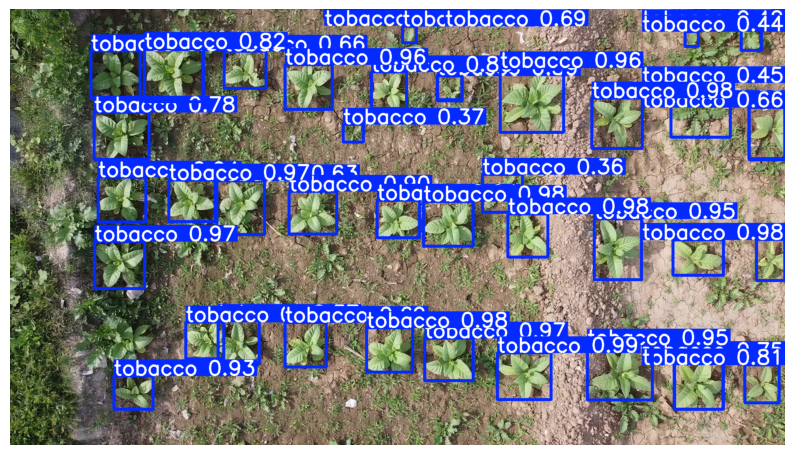

In [10]:

results = model([DATASET_PATH / "images" / "00a357bc-17.jpg"], device=device)  # return a list of Results objects

# Process results list
for result in results:
    boxes = result.boxes  # Boxes object for bounding box outputs
    masks = result.masks  # Masks object for segmentation masks outputs
    keypoints = result.keypoints  # Keypoints object for pose outputs
    probs = result.probs  # Probs object for classification outputs
    obb = result.obb  # Oriented boxes object for OBB outputs
    # result.show()  # display to screen
    annotated_img_point = result.plot()
    annotated_img_point = cv2.cvtColor(annotated_img_point, cv2.COLOR_BGR2RGB)

    # Отображаем результат
    plt.figure(figsize=(10, 8))
    plt.imshow(annotated_img_point)
    plt.axis("off")
    plt.show()


0: 384x640 44 tobaccos, 7.0ms
Speed: 1.1ms preprocess, 7.0ms inference, 0.5ms postprocess per image at shape (1, 3, 384, 640)


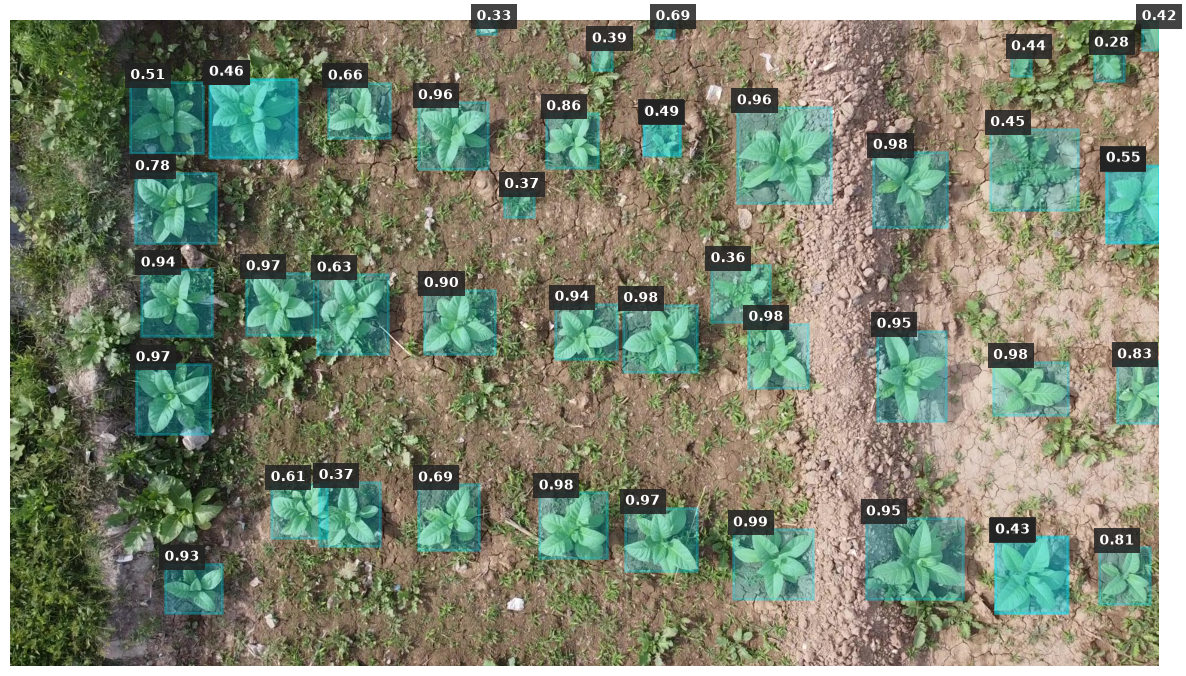

In [14]:
results = model([DATASET_PATH / "images" / "00a357bc-17.jpg"], device=device)

for result in results:
    img = cv2.cvtColor(result.orig_img, cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(img)

    if result.boxes is not None:
        for box in result.boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

            cls_id = int(box.cls[0])
            conf = float(box.conf[0])

            class_name = result.names[cls_id]

            # Your own custom style
            color = "#00E5FF"

            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=2,
                edgecolor=color,
                facecolor=color,
                alpha=0.25
            )

            ax.add_patch(rect)

            # Label with background
            ax.text(
                x1,
                max(0, y1 - 5),
                # f"{class_name} {conf:.2f}",
                f"{conf:.2f}",
                color="white",
                fontsize=10,
                fontweight="bold",
                bbox={
                    "facecolor": "#222222",
                    "alpha": 0.85,
                    "edgecolor": "none",
                    "pad": 4
                }
            )

    ax.axis("off")
    plt.tight_layout()
    plt.show()

Проверка fps

In [12]:
img = cv2.imread(str(DATASET_PATH / "images" / "00a357bc-17.jpg"))

def synchronize():
    if str(model.device).startswith("cuda"):
        torch.cuda.synchronize(model.device)
    elif str(model.device).startswith("mps"):
        torch.mps.synchronize()

print(f"Timing device: {model.device}")

# Warmup
for _ in range(200):
    model.predict(img, verbose=False, device=device)

synchronize()

latencies = []

# Benchmark
for _ in range(2000):
    synchronize()
    start = time.perf_counter()

    results = model.predict(
        img,
        device=device,
        verbose=False,
        imgsz=640,
        conf=0.5
    )

    # Simulate decision-making from detections
    boxes = results[0].boxes

    if boxes is not None and len(boxes) > 0:
        # Example: make a decision based on class IDs
        detected_classes = boxes.cls.cpu().numpy()
        obstacle_detected = np.any(detected_classes == 0)
    else:
        obstacle_detected = False

    synchronize()
    latencies.append(
        (time.perf_counter() - start) * 1000
    )

latencies = np.array(latencies)

print(f"Mean latency: {latencies.mean():.2f} ms")
print(f"Median latency: {np.median(latencies):.2f} ms")
print(f"P95 latency: {np.percentile(latencies, 95):.2f} ms")
print(f"P99 latency: {np.percentile(latencies, 99):.2f} ms")
print(f"Estimated FPS: {1000 / latencies.mean():.2f}")

Mean latency: 6.77 ms
Median latency: 6.74 ms
P95 latency: 7.14 ms
P99 latency: 7.77 ms
Estimated FPS: 147.75


In [13]:
def synthetic_stream(image, fps=30):
    interval = 1.0 / fps
    next_frame_time = time.perf_counter()

    while True:
        now = time.perf_counter()

        if now < next_frame_time:
            time.sleep(next_frame_time - now)

        yield image.copy()

        next_frame_time += interval

        # Skip missed slots instead of accumulating delay
        now = time.perf_counter()
        if next_frame_time < now:
            next_frame_time = now

In [14]:
img = cv2.imread(
    str(DATASET_PATH / "images" / "00a357bc-17.jpg")
)

stream = synthetic_stream(img, fps=30)

start = time.perf_counter()
frame_count = 0

for frame in stream:
    results = model.predict(
        frame,
        device=device,
        verbose=False,
        imgsz=640
    )

    result = results[0]

    # Example decision logic
    boxes = result.boxes
    obstacle_detected = boxes is not None and len(boxes) > 0

    action = "STOP" if obstacle_detected else "MOVE"

    frame_count += 1

    if frame_count >= 300:
        break

elapsed = time.perf_counter() - start

print(f"Actual processing FPS: {frame_count / elapsed:.2f}")

Actual processing FPS: 30.07


In [15]:
import queue
import threading

from ultralytics.data.loaders import LoadStreams, SourceTypes


class SyntheticStream(LoadStreams):
    def __init__(self, image, fps=30):
        # Do not call super().__init__():
        # that would try to open a real camera/URL.
        if image is None or fps <= 0:
            raise ValueError("Provide a valid image and positive FPS")

        self.image = image
        self.fps = [fps]
        self.bs = 1
        self.mode = "stream"
        self.count = -1
        self.running = True
        self.source_type = SourceTypes(stream=True)

        self.frames = queue.Queue(maxsize=1)
        self.stop_event = threading.Event()

        self.thread = threading.Thread(
            target=self._produce,
            daemon=True
        )
        self.thread.start()

    def _produce(self):
        interval = 1 / self.fps[0]
        next_time = time.perf_counter()

        while not self.stop_event.is_set():
            if self.stop_event.wait(
                max(0, next_time - time.perf_counter())
            ):
                break

            frame = self.image.copy()

            # Keep only the newest frame
            if self.frames.full():
                try:
                    self.frames.get_nowait()
                except queue.Empty:
                    pass

            self.frames.put_nowait(frame)

            next_time += interval

            if next_time < time.perf_counter():
                next_time = time.perf_counter()

    def __iter__(self):
        return self

    def __next__(self):
        if self.stop_event.is_set():
            raise StopIteration

        frame = self.frames.get(timeout=5)
        self.count += 1

        return ["synthetic.jpg"], [frame], [""]

    def __len__(self):
        return self.bs

    def close(self):
        self.stop_event.set()
        self.running = False
        self.thread.join()

In [16]:
img = cv2.imread(
    str(DATASET_PATH / "images" / "00a357bc-17.jpg")
)

stream = SyntheticStream(img, fps=300)

latencies = []

try:
    results = model.predict(
        source=stream,
        device=device,
        stream=True,
        imgsz=640,
        verbose=False,
        save=False,
        show=False
    )

    start = time.perf_counter()
    frame_count = 0

    for result in results:
        start_2 = time.perf_counter()
        boxes = result.boxes

        # Robot logic
        obstacle_detected = boxes is not None and len(boxes) > 0
        action = "STOP" if obstacle_detected else "MOVE"

        frame_count += 1

        if frame_count >= 300:
            break

        latencies.append((time.perf_counter() - start_2) * 1000)

    elapsed = time.perf_counter() - start

    print(f"Processed: {frame_count} frames")
    print(f"Effective FPS: {frame_count / elapsed:.2f}")

finally:
    stream.close()

plt.plot(latencies)

Processed: 300 frames
Effective FPS: 126.13
